# Importo librerias

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Cargo Datos Bencina Chile

In [3]:
df_precios_bencinas=pd.read_csv(r"C:\Users\ggalv\Downloads\Analisis_bencinas\precios_bencina_chile\2026.csv",sep=",")
df_precios_bencinas=df_precios_bencinas[(df_precios_bencinas['nom_region'] == 'Metropolitana de Santiago') & 
                                        (df_precios_bencinas['unidad_cobro'] == '$/L') &
                                        (df_precios_bencinas['precio'] <= 3000) &
                                        (df_precios_bencinas['combustible'] == "93")
                                        ].copy()

C:\Users\ggalv\AppData\Local\Temp\ipykernel_11344\4254508971.py:1: DtypeWarning: Columns (0: latitud, 1: longitud) have mixed types. Specify dtype option on import or set low_memory=False.
  df_precios_bencinas=pd.read_csv(r"C:\Users\ggalv\Downloads\Analisis_bencinas\precios_bencina_chile\2026.csv",sep=",")


In [4]:
df_precios_bencinas.head(10)

,codigo,razon_social,distribuidor,direccion,latitud,longitud,nom_comuna,nom_region,combustible,precio,unidad_cobro,atencion,fecha_actualizacion,hora_actualizacion,es_electrolinera,es_gasolinera
105187,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1133.0,$/L,Asistido,2026-01-01,12:50:12,0,1
105188,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1134.0,$/L,Asistido,2026-01-02,14:54:40,0,1
105189,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1110.0,$/L,Asistido,2026-01-22,8:18:44,0,1
105190,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1123.0,$/L,Asistido,2026-02-12,9:07:11,0,1
105191,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1142.0,$/L,Asistido,2026-03-05,21:39:29,0,1
105192,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1140.0,$/L,Asistido,2026-03-16,14:46:12,0,1
105193,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1115.0,$/L,Asistido,2026-03-17,20:10:54,0,1
105194,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1142.0,$/L,Asistido,2026-03-18,17:29:33,0,1
105195,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1515.0,$/L,Asistido,2026-03-26,6:04:01,0,1
105196,co01001,Sociedad Comercial E Inversiones V&G ltda,COPEC,Mapocho 1998,-33.43219,-70.66466,Santiago Centro,Metropolitana de Santiago,93,1528.0,$/L,Asistido,2026-04-16,12:11:33,0,1


In [5]:
df_precios_bencinas.info()
df_precios_bencinas.describe()

<class 'pandas.DataFrame'>
Index: 7062 entries, 105187 to 152258
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   codigo               7062 non-null   str    
 1   razon_social         7062 non-null   str    
 2   distribuidor         7062 non-null   str    
 3   direccion            7062 non-null   str    
 4   latitud              7062 non-null   object 
 5   longitud             7062 non-null   object 
 6   nom_comuna           7062 non-null   str    
 7   nom_region           7062 non-null   str    
 8   combustible          7062 non-null   str    
 9   precio               7062 non-null   float64
 10  unidad_cobro         7062 non-null   str    
 11  atencion             7062 non-null   str    
 12  fecha_actualizacion  7062 non-null   str    
 13  hora_actualizacion   7062 non-null   str    
 14  es_electrolinera     7062 non-null   int64  
 15  es_gasolinera        7062 non-null   int64  
dt

,precio,es_electrolinera,es_gasolinera
count,7062.000000,7062.000000,7062.0
mean,1384.822161,0.034410,1.0
std,171.422425,0.182292,0.0
min,1.000000,0.000000,1.0
25%,1185.250000,0.000000,1.0
50%,1456.000000,0.000000,1.0
75%,1511.000000,0.000000,1.0
max,1744.000000,1.000000,1.0


<Axes: xlabel='precio', ylabel='Count'>

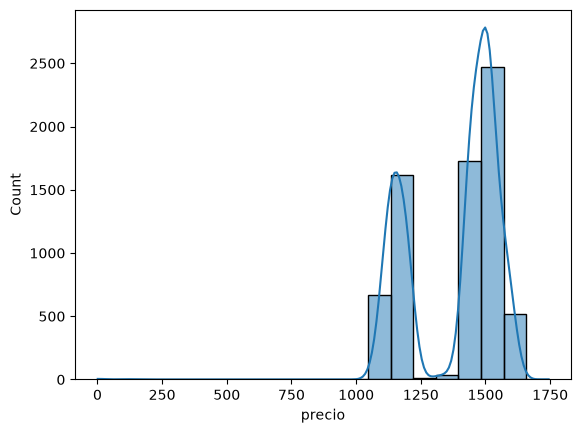

In [6]:
sns.histplot(data=df_precios_bencinas, x='precio', bins=20, kde=True, log_scale=False)

In [7]:
# Agrupo el precio por semana del año y calculo la media de cada semana
df_precios_bencinas['fecha_actualizacion'] = pd.to_datetime(df_precios_bencinas['fecha_actualizacion'])
df_precios_bencinas['semana'] = df_precios_bencinas['fecha_actualizacion'].dt.isocalendar().week

In [8]:
# Preparar los datos agregados
df_semanal = df_precios_bencinas.groupby('semana')['precio'].mean().reset_index()
df_semanal.head(10)

,semana,precio
0,1,1161.080519
1,2,1162.271186
2,3,1161.403846
3,4,1138.430131
4,5,1137.437500
5,6,1112.333333
6,7,1147.850962
7,8,1134.903226
8,9,1127.000000
9,10,1169.058594


# Descargo Datos de Precio Curdo Petroleo por Barril

In [10]:
url_brent = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=WCOILBRENTEU&cosd=2024-01-01"
df_brent = pd.read_csv(url_brent)
df_brent.columns = ['fecha', 'brent_usd']
df_brent['fecha'] = pd.to_datetime(df_brent['fecha'])
df_brent = df_brent.sort_values('fecha').reset_index(drop=True)

# Numerar semanas correlativas (ISO week, no solo semana del año calendario)
df_brent['semana_iso'] = df_brent['fecha'].dt.isocalendar().week
df_brent['anio'] = df_brent['fecha'].dt.isocalendar().year

In [ ]:
# Preparo los datos agregados del Brent
df_precios_bencinas['fecha_actualizacion'] = pd.to_datetime(df_precios_bencinas['fecha_actualizacion'])
df_precios_bencinas['semana_iso'] = df_precios_bencinas['fecha_actualizacion'].dt.isocalendar().week
df_precios_bencinas['anio'] = df_precios_bencinas['fecha_actualizacion'].dt.isocalendar().year

df_bencina_semanal = (
    df_precios_bencinas
    .groupby(['anio', 'semana_iso'])['precio']
    .mean()
    .reset_index()
)

df_merged = pd.merge(
    df_bencina_semanal,
    df_brent.groupby(['anio', 'semana_iso'])['brent_usd'].mean().reset_index(),
    on=['anio', 'semana_iso'],
    how='inner'
)

# Ordeno cronológicamente y creo un eje temporal continuo
df_merged = df_merged.sort_values(['anio', 'semana_iso']).reset_index(drop=True)
df_merged['periodo'] = df_merged['anio'].astype(str) + '-S' + df_merged['semana_iso'].astype(str)

# Aplico el rezago del MEPCO (promedio móvil de 4 semanas del Brent)
df_merged['brent_ma4'] = df_merged['brent_usd'].rolling(window=4, min_periods=1).mean()

#Calculo la correlación entre los precios de bencina y el Brent spot y el Brent rezagado
corr_directa = df_merged['precio'].corr(df_merged['brent_usd'])
corr_rezagada = df_merged['precio'].corr(df_merged['brent_ma4'])

# Grafico Ambos Datos

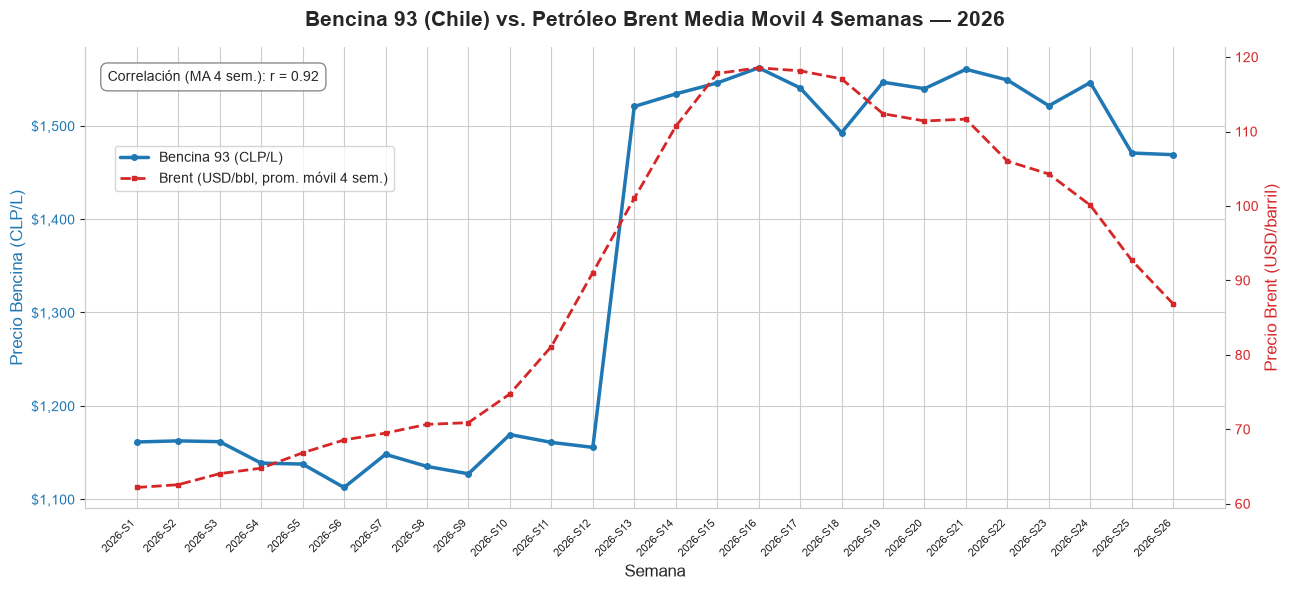

In [34]:
# Grafico el doble eje con etiqueta de correlación

sns.set_style("whitegrid")
fig, ax1 = plt.subplots(figsize=(13, 6))

color_bencina = '#1f77b4'
color_brent = '#d62728'

ax1.plot(df_merged['periodo'], df_merged['precio'],
         color=color_bencina, linewidth=2.5, marker='o', markersize=4,
         label='Bencina 93 (CLP/L)')
ax1.set_ylabel('Precio Bencina (CLP/L)', color=color_bencina, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_bencina)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

ax2 = ax1.twinx()
ax2.plot(df_merged['periodo'], df_merged['brent_ma4'],
         color=color_brent, linewidth=2, linestyle='--', marker='s', markersize=3,
         label='Brent (USD/bbl, prom. móvil 4 sem.)')
ax2.set_ylabel('Precio Brent (USD/barril)', color=color_brent, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_brent)
ax2.grid(False)

ax1.set_title('Bencina 93 (Chile) vs. Petróleo Brent Media Movil 4 Semanas — 2026',
               fontsize=15, fontweight='bold', pad=15)
ax1.set_xlabel('Semana', fontsize=12)

step = max(1, len(df_merged) // 20)
ax1.set_xticks(df_merged['periodo'][::step])
ax1.set_xticklabels(df_merged['periodo'][::step], rotation=45, ha='right', fontsize=8)

# --- Etiqueta de correlación (recuadro dentro del gráfico) ---
texto_corr = (
    
    f"Correlación (MA 4 sem.): r = {corr_rezagada:.2f}"
)
ax1.text(
    0.02, 0.95, texto_corr,
    transform=ax1.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.9)
)

# Leyenda combinada
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left',
           bbox_to_anchor=(0.02, 0.80), frameon=True)

sns.despine(right=False)
plt.tight_layout()
plt.savefig('C:\\Users\\ggalv\\Downloads\\Analisis_bencinas\\bencina_vs_brentMA4.png', dpi=150, bbox_inches='tight')
plt.show()



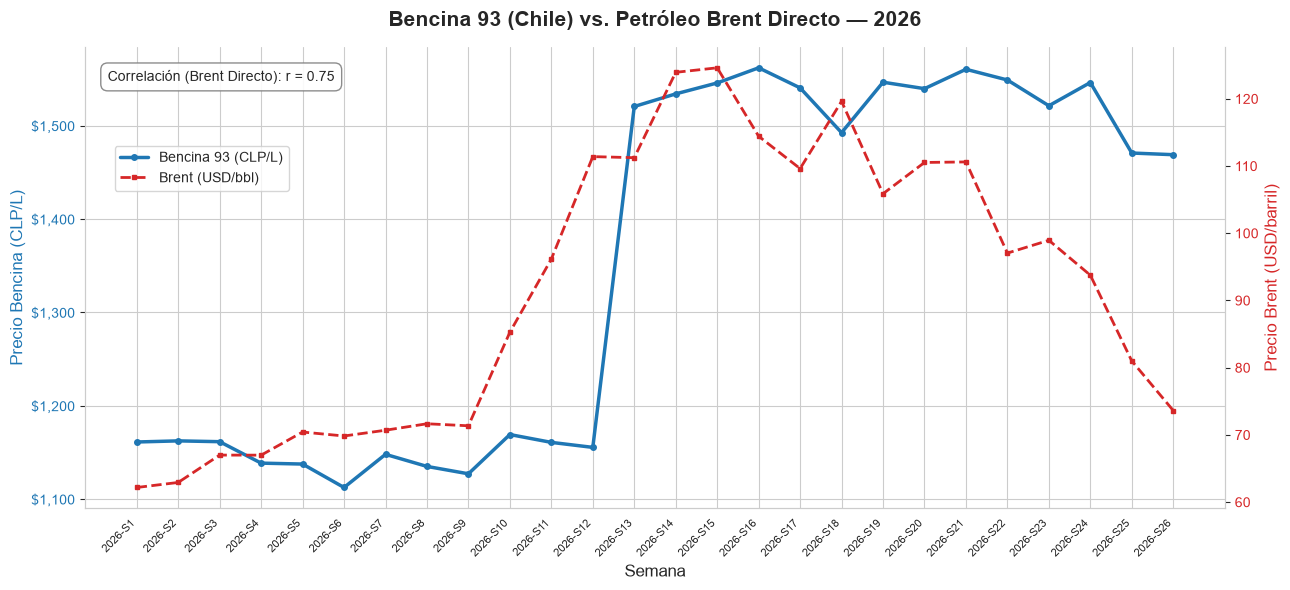

In [33]:
# Grafico el doble eje con etiqueta de correlación

sns.set_style("whitegrid")
fig, ax1 = plt.subplots(figsize=(13, 6))

color_bencina = '#1f77b4'
color_brent = '#d62728'

ax1.plot(df_merged['periodo'], df_merged['precio'],
         color=color_bencina, linewidth=2.5, marker='o', markersize=4,
         label='Bencina 93 (CLP/L)')
ax1.set_ylabel('Precio Bencina (CLP/L)', color=color_bencina, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_bencina)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

ax2 = ax1.twinx()
ax2.plot(df_merged['periodo'], df_merged['brent_usd'],
         color=color_brent, linewidth=2, linestyle='--', marker='s', markersize=3,
         label='Brent (USD/bbl)')
ax2.set_ylabel('Precio Brent (USD/barril)', color=color_brent, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_brent)
ax2.grid(False)

ax1.set_title('Bencina 93 (Chile) vs. Petróleo Brent Directo — 2026',
               fontsize=15, fontweight='bold', pad=15)
ax1.set_xlabel('Semana', fontsize=12)

step = max(1, len(df_merged) // 20)
ax1.set_xticks(df_merged['periodo'][::step])
ax1.set_xticklabels(df_merged['periodo'][::step], rotation=45, ha='right', fontsize=8)

# --- Etiqueta de correlación (recuadro dentro del gráfico) ---
texto_corr = (
    
    f"Correlación (Brent Directo): r = {corr_directa:.2f}"
)
ax1.text(
    0.02, 0.95, texto_corr,
    transform=ax1.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.9)
)

# Leyenda combinada
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left',
           bbox_to_anchor=(0.02, 0.80), frameon=True)

sns.despine(right=False)
plt.tight_layout()
plt.savefig('C:\\Users\\ggalv\\Downloads\\Analisis_bencinas\\bencina_vs_brent.png', dpi=150, bbox_inches='tight')
plt.show()

